# 02 · Data profiling

Measure the audio before defining cleaning rules.

**Input:** `01_ingested.jsonl`  
**Output:** `02_profiled.jsonl` plus duration, level, format, and review-flag summaries

Quiet, saturated, and short recordings are flagged for inspection. They are not deleted in this stage.

## 1. Load the ingestion manifest

In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json, wave
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Audio

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
output = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
source_rows = [json.loads(line) for line in (output/"01_ingested.jsonl").read_text().splitlines()]
print(f"Loaded {len(source_rows):,} source records")

Loaded 8,000 source records


## 2. Decode one PCM16 WAV file

The parser validates encoding and returns floating-point samples in full-scale units.

### Math for the next code block — PCM16 to full-scale amplitude

Let $q_{n,c}\in[-32768,32767]$ be PCM16 sample $n$ in channel $c$. It becomes

$$x_{n,c}=\frac{q_{n,c}}{32768},\qquad x_{n,c}\in[-1,1).$$

For $N$ frames sampled at $f_s$ hertz, duration is $T=N/f_s$ seconds. The returned audio array has shape $N\times C$.

In [2]:
def read_audio(path):
    with wave.open(str(path), "rb") as wav:
        rate, channels = wav.getframerate(), wav.getnchannels()
        width, frames = wav.getsampwidth(), wav.getnframes()
        if wav.getcomptype() != "NONE" or width != 2:
            raise ValueError("Only uncompressed PCM16 WAV is supported")
        pcm = wav.readframes(frames)
    if not frames or len(pcm) != frames * channels * width:
        raise ValueError("Empty or truncated PCM")
    audio = np.frombuffer(pcm,dtype="<i2").reshape(-1,channels).astype(np.float32)/32768
    meta = {"sample_rate":rate,"channels":channels,"sample_width":width,"frames":frames,
            "pcm_sha256":hashlib.sha256(pcm).hexdigest()}
    return audio, meta

## 3. Measure one recording at a time

RMS uses the whole clip because verified speech boundaries are unavailable.

### Math for the next code block — review decisions

Each flag is an indicator, not a deletion rule:

$$I_{\text{quiet}}=\mathbf{1}[L_{\mathrm{dBFS}}<L_{\min}],\quad
I_{\text{sat}}=\mathbf{1}[p_{\text{sat}}>0],\quad
I_{\text{short}}=\mathbf{1}[T<1\ \mathrm{s}].$$

Here $L_{\min}=-50$ dBFS for the current configuration.

In [3]:
def review_flags(record):
    flags = []
    if record["rms_dbfs"] < cfg["quiet_dbfs"]: flags.append("low_level_review")
    if record["saturation_fraction"] > 0: flags.append("saturated_samples_review")
    if record["duration_seconds"] < 1: flags.append("shorter_than_one_second")
    return flags

### Math for the next code block — waveform measurements

For $N$ samples $x_n$ across the whole recording:

$$x_{\mathrm{RMS}}=\sqrt{\frac1N\sum_{n=0}^{N-1}x_n^2},\qquad
L_{\mathrm{dBFS}}=20\log_{10}\!\left(\max(x_{\mathrm{RMS}},10^{-12})\right).$$

$$x_{\mathrm{peak}}=\max_n|x_n|,\qquad
x_{\mathrm{DC}}=\frac1N\sum_n x_n,$$

$$p_{\mathrm{sat}}=\frac1N\sum_n\mathbf{1}\!\left[x_n\ge\frac{32767}{32768}\ \lor\ x_n\le-1\right].$$

The RMS is whole-clip RMS because verified speech boundaries are unavailable.

In [4]:
def profile(row):
    record = dict(row)
    try:
        audio, meta = read_audio(root/record["raw_path"])
        rms = float(np.sqrt(np.mean(audio.astype(np.float64)**2)))
        record.update(meta, duration_seconds=len(audio)/meta["sample_rate"], rms=rms,
                      rms_dbfs=20*np.log10(max(rms,1e-12)), peak=float(np.max(np.abs(audio))),
                      dc_offset=float(np.mean(audio)),
                      saturation_fraction=float(np.mean((audio>=32767/32768)|(audio<=-1))), valid=True)
        record["flags"] = review_flags(record)
    except (ValueError,wave.Error,EOFError) as error:
        record.update(valid=False,error=str(error),flags=["invalid_audio"])
    return record

In [5]:
profiled = [profile(row) for row in source_rows]
with (output/"02_profiled.jsonl").open("w") as stream:
    for row in profiled:
        stream.write(json.dumps(row,allow_nan=False)+"\n")

flag_counts = Counter(flag for row in profiled for flag in row["flags"])
summary = {"total":len(profiled),"valid":sum(row["valid"] for row in profiled),
           "flags":dict(flag_counts),"word_counts":dict(Counter(row["word"] for row in profiled))}
reports.mkdir(parents=True,exist_ok=True)
(reports/"profile.json").write_text(json.dumps(summary,indent=2)+"\n")
display(summary)

{'total': 8000,
 'valid': 8000,
 'flags': {'shorter_than_one_second': 822,
  'saturated_samples_review': 363,
  'low_level_review': 204},
 'word_counts': {'down': 1000,
  'go': 1000,
  'left': 1000,
  'no': 1000,
  'right': 1000,
  'stop': 1000,
  'up': 1000,
  'yes': 1000}}

## 4. Read the distributions together

The panels answer different questions: Do files have the expected duration? Are any unusually quiet? How many records need human review? Flag counts can overlap.

In [6]:
durations=np.array([r["duration_seconds"] for r in profiled if r["valid"]])
levels=np.array([r["rms_dbfs"] for r in profiled if r["valid"]])
names=("low_level_review","saturated_samples_review","shorter_than_one_second")
counts=[flag_counts[name] for name in names]

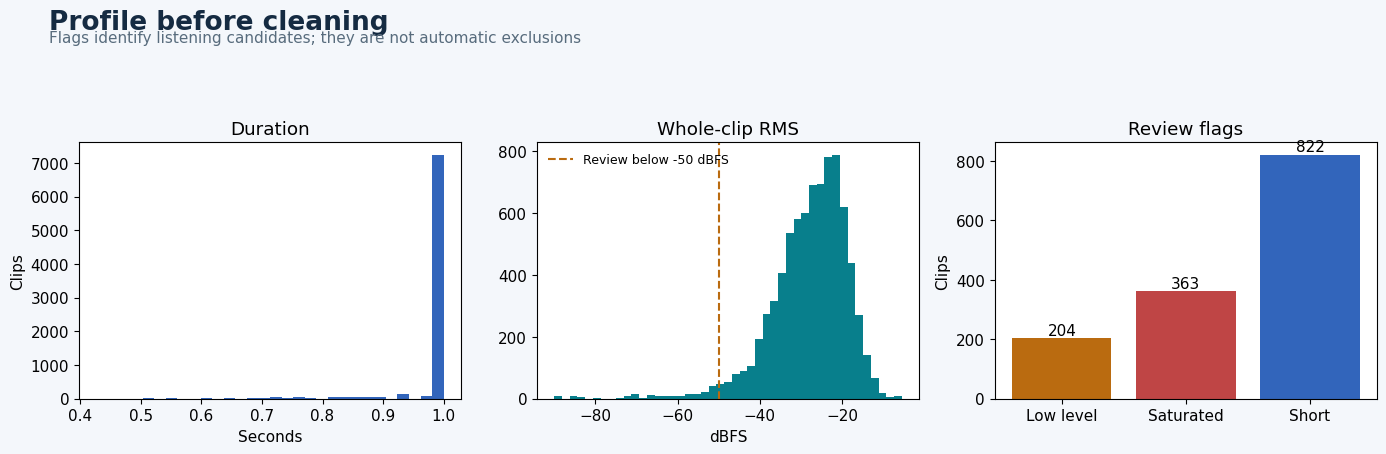

In [7]:
INK,BLUE,TEAL,AMBER,RED="#152b42","#3265bb","#087f8c","#ba6b10","#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb","axes.facecolor":"white","font.size":11})
fig,axes=plt.subplots(1,3,figsize=(14,4.7))
axes[0].hist(durations,bins=30,color=BLUE); axes[0].set(title="Duration",xlabel="Seconds",ylabel="Clips")
axes[1].hist(levels,bins=45,color=TEAL); axes[1].axvline(cfg["quiet_dbfs"],color=AMBER,ls="--",label=f"Review below {cfg['quiet_dbfs']} dBFS"); axes[1].set(title="Whole-clip RMS",xlabel="dBFS"); axes[1].legend(frameon=False,fontsize=9)
bars=axes[2].bar(["Low level","Saturated","Short"],counts,color=[AMBER,RED,BLUE]); axes[2].bar_label(bars); axes[2].set(title="Review flags",ylabel="Clips")
fig.suptitle("Profile before cleaning",x=.04,ha="left",fontsize=19,weight="bold",color=INK)
fig.text(.04,.91,"Flags identify listening candidates; they are not automatic exclusions",color="#586c7d")
fig.tight_layout(rect=(0,.02,1,.87)); figures=reports/"figures"; figures.mkdir(parents=True,exist_ok=True)
fig.savefig(figures/"02_raw_profile.png",dpi=170,bbox_inches="tight"); fig.savefig(figures/"02_raw_profile.svg",bbox_inches="tight"); plt.show()

## 5. Inspect records behind the summary

The first table shows the manifest fields passed to cleaning. The audio player is a human spot check and does not count as a completed label audit.

In [8]:
columns=("id","word","duration_seconds","rms_dbfs","peak","flags")
display([{column:row[column] for column in columns} for row in profiled[:5]])

keywords=sorted([r for r in profiled if r["is_keyword"]],key=lambda r:(r["rms_dbfs"],r["id"]))
example=keywords[len(keywords)//2]
print("Playback example:",example["id"],"· flags:",example["flags"])
display(Audio(filename=str(root/example["raw_path"])))

[{'id': 'down__004ae714_nohash_0',
  'word': 'down',
  'duration_seconds': 1.0,
  'rms_dbfs': np.float64(-27.996361793343894),
  'peak': 0.463592529296875,
  'flags': []},
 {'id': 'down__00b01445_nohash_1',
  'word': 'down',
  'duration_seconds': 1.0,
  'rms_dbfs': np.float64(-23.293236763436703),
  'peak': 0.5355224609375,
  'flags': []},
 {'id': 'down__00f0204f_nohash_0',
  'word': 'down',
  'duration_seconds': 1.0,
  'rms_dbfs': np.float64(-32.62309132658415),
  'peak': 0.195831298828125,
  'flags': []},
 {'id': 'down__0132a06d_nohash_1',
  'word': 'down',
  'duration_seconds': 1.0,
  'rms_dbfs': np.float64(-29.366965120930164),
  'peak': 0.241912841796875,
  'flags': []},
 {'id': 'down__0132a06d_nohash_4',
  'word': 'down',
  'duration_seconds': 1.0,
  'rms_dbfs': np.float64(-21.14492064181117),
  'peak': 0.62384033203125,
  'flags': []}]

Playback example: stop__3a789a0d_nohash_0 · flags: []


## What the profile says

- All 8,000 files decode as valid audio.
- Most clips are one second; 822 are shorter.
- 204 low-level and 363 saturation flags identify review candidates.
- These observations do not justify deleting difficult examples.
- Transcript and boundary review still require human work.

Continue with [03 · Data cleaning](03_data_cleaning.ipynb).